# Imports

In [1]:
import pandas as pd
import warnings
import sqlite3
import urllib.request
import geopandas as gpd
import matplotlib.pyplot as plt

# Load Required Data

## Load all CSV files

In [2]:
facilities_url = 'https://raw.githubusercontent.com/RollieGarcia0031/CPE-15-lec/refs/heads/main/final-project/Operation%20Blank%20Map%20-%20STUDENT%20PACKAGE/data/facilities.csv'
household_url = 'https://raw.githubusercontent.com/RollieGarcia0031/CPE-15-lec/refs/heads/main/final-project/Operation%20Blank%20Map%20-%20STUDENT%20PACKAGE/data/household_access.csv'
risk_index_url = 'https://raw.githubusercontent.com/RollieGarcia0031/CPE-15-lec/refs/heads/main/final-project/Operation%20Blank%20Map%20-%20STUDENT%20PACKAGE/data/risk_index.csv'
gjson_url = 'https://raw.githubusercontent.com/RollieGarcia0031/CPE-15-lec/refs/heads/main/final-project/Operation%20Blank%20Map%20-%20STUDENT%20PACKAGE/data/zones.geojson'

warnings.filterwarnings('ignore')

facilities_df = pd.read_csv(facilities_url)
household_df = pd.read_csv(household_url)
risk_index_df = pd.read_csv(risk_index_url)
gdf = gpd.read_file(gjson_url)

print('Loaded Facilities Rows: ', len(facilities_df))
print('Loaded Household Rows: ', len(household_df))
print('Loaded Risk Index Rows: ', len(risk_index_df))
print('Geojson  Rows: ', len(gdf))

Loaded Facilities Rows:  5
Loaded Household Rows:  13
Loaded Risk Index Rows:  13
Geojson  Rows:  12


## Load SQL file

In [3]:
sql_url = "https://raw.githubusercontent.com/RollieGarcia0031/CPE-15-lec/main/final-project/Operation%20Blank%20Map%20-%20STUDENT%20PACKAGE/data/service_requests.sqlite?raw=true"
SQL_FILENAME = "service_requests.sqlite"

urllib.request.urlretrieve(sql_url, SQL_FILENAME)
with sqlite3.connect(SQL_FILENAME) as con:
    requests = pd.read_sql_query('SELECT * FROM requests', con)

print('Requests loaded: ', len(requests))

Requests loaded:  397


## CRS Declaration

In [4]:
METRIC_CRS = "EPSG:32651"
WGS84 = "EPSG:4326"

# Problems

In [5]:
household_zone_codes = household_df['zone_code']
risk_index_zone_codes = risk_index_df['zone_code']

household_dup_mask = household_zone_codes.duplicated()
risk_index_dup_mask = risk_index_zone_codes.duplicated()

print('Household zone codes all:\t', list(household_zone_codes))
print('Household zone codes unique:\t', list(household_zone_codes.unique()))
print('Household zone codes count:\t', len(household_zone_codes))
print('zone codes unique count:\t', len(household_zone_codes.unique()))
print('Household zone codes dup:\t', sum(household_zone_codes.duplicated()))
print('duplicated zone code:\t\t',
      list(household_zone_codes[household_dup_mask]))
print()
print('Risk Index zone codes all:\t', list(risk_index_zone_codes))
print('Risk Index zone codes unique:\t', list(risk_index_zone_codes.unique()))
print('zone codes unique:\t\t', len(risk_index_zone_codes.unique()))
print('Risk Index zone codes count:\t', len(risk_index_zone_codes))
print('Risk Index zone codes dupp:\t', sum(risk_index_zone_codes.duplicated()))
print('duplicated zone codes:\t\t',
      list(risk_index_zone_codes[risk_index_dup_mask]))

print()
req_zone_code = requests['zone_code']

print('Requests zone codes unique:\t', list(req_zone_code.unique()))
print('Requests zone codes count:\t', len(req_zone_code.unique()))
print('Requests zone codes dupp:\t', sum(req_zone_code.duplicated()))

Household zone codes all:	 ['A01', 'A02', 'A-03', 'A04', 'A05', 'A06', 'A07', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']
Household zone codes unique:	 ['A01', 'A02', 'A-03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']
Household zone codes count:	 13
zone codes unique count:	 12
Household zone codes dup:	 1
duplicated zone code:		 ['A07']

Risk Index zone codes all:	 ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A09']
Risk Index zone codes unique:	 ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']
zone codes unique:		 12
Risk Index zone codes count:	 13
Risk Index zone codes dupp:	 1
duplicated zone codes:		 ['A09']

Requests zone codes unique:	 ['A09', 'A11', 'A03', 'A05', 'A08', 'A10', 'A06', 'A02', 'A12', 'A04', 'A01', 'A-03', 'A07']
Requests zone codes count:	 13
Requests zone codes dupp:	 384


## Problem 1: `zone_code` Inconsistency
1. household data has msispeled `zone_code`
2. risk index data has duplicaeted `zone_code`
3. requests has misspelled `A03` to `A-03` 

## Problem 2: Missing Household Data
Household data has 1 record with a missing data on `household_With_access`

In [6]:
household_cols = list(household_df.columns)

display(household_df)

missing_hh_access = household_df['households_with_access'].isna().sum()
print("Missing household access record:", int(missing_hh_access))

,zone_code,total_households,households_with_access
0,A01,850,520.0
1,A02,700,238.0
2,A-03,500,228.0
3,A04,350,260.0
4,A05,460,325.0
5,A06,820,NaN
6,A07,1100,400.0
7,A07,1100,400.0
8,A08,650,150.0
9,A09,500,220.0


Missing household access record: 1


## Problem 3: Requests Duplicate
Requests has **3 duplicated rows**

In [7]:
dup_mask = requests['request_id'].duplicated(keep=False)
dup_df = requests.loc[dup_mask]
dup_df = dup_df.sort_values(by='request_id')
dup_df

,request_id,zone_code,request_type,status,requested_at
109,REQ-A01-0008,A01,training,verified,2026-09-09
331,REQ-A01-0008,A01,training,verified,2026-09-09
116,REQ-A03-0017,A03,connectivity,verified,2026-09-18
373,REQ-A03-0017,A03,connectivity,verified,2026-09-18
161,REQ-A06-0006,A06,training,open,2026-09-07
226,REQ-A06-0006,A06,training,open,2026-09-07


## Problem 4: Conflicting Count of Household
Verify if the number of `total_households` is greater then the `house`

In [8]:
miscount_mask = household_df['households_with_access'] > household_df['total_households']
print("Miscounts: ", miscount_mask.sum())
display(household_df[miscount_mask])

Miscounts:  1


,zone_code,total_households,households_with_access
11,A11,780,1220.0


## Problem 5: Requests Status
Some status `canceled` and `invalid` are inegligeble

In [9]:
status_df = pd.DataFrame(requests['status'].value_counts())
display(status_df)

,count
status,
verified,223
open,102
invalid,36
cancelled,36


## Problem 6: Duplicate `risk_index` record
zone A09 has been recorded twice in the `risk_index` dataframe

In [10]:
mask = risk_index_df['zone_code'].duplicated(keep=False)
print('Duplicated rows: ')
risk_index_df.loc[mask]

Duplicated rows: 


,zone_code,risk_score
8,A09,72
12,A09,96


# Fixes

## Create copies of dataframes

In [11]:
household_df_clean = household_df.copy()
risk_index_df_clean = risk_index_df.copy()
facilities_df_clean = facilities_df.copy()
requests_clean = requests.copy()

## Fix 1

### Fix 1.1
Replace the `zone_code` of `household_df` field with correct format

In [12]:
# Display zone codes in household_df
zone_list = list(household_df['zone_code'].unique())
print('Raw Zones:\t',", ".join(zone_list))
zone_code_map = {
    'A-03': 'A03'
}

household_df_clean['zone_code'] = household_df_clean['zone_code'].replace(zone_code_map)
print('Cleaned Zones:\t', ", ".join(list(household_df_clean['zone_code'])))

Raw Zones:	 A01, A02, A-03, A04, A05, A06, A07, A08, A09, A10, A11, A12
Cleaned Zones:	 A01, A02, A03, A04, A05, A06, A07, A07, A08, A09, A10, A11, A12


In [13]:
facilities_df_clean

,facility_id,facility_name,longitude,latitude,status
0,F01,Scenario Assistance Hub — Kalangay,121.552,14.1570,operational
1,F02,Scenario Assistance Hub — Kilib,121.570,14.1275,operational
2,F03,Scenario Assistance Hub — Nagsinamo,121.602,14.1100,operational
3,F04,Scenario Assistance Hub — Tiawe,121.595,14.0817,operational
4,F05,Scenario Assistance Hub — Kalyaat,121.530,14.1427,operational


### Fix 1.2 Duplicate Household
Drop the duplicated row of `household_df`

In [14]:
dup = household_df.duplicated(keep=False)
print('Dupilcated Row: ', dup.sum())
display(household_df[dup])
print()

# drop duplicated rows:
household_df_clean = household_df_clean.drop_duplicates()
print('Duplicated in Cleaned DF:',
      household_df_clean.duplicated().sum())
display(household_df_clean)

Dupilcated Row:  2


,zone_code,total_households,households_with_access
6,A07,1100,400.0
7,A07,1100,400.0



Duplicated in Cleaned DF: 0


,zone_code,total_households,households_with_access
0,A01,850,520.0
1,A02,700,238.0
2,A03,500,228.0
3,A04,350,260.0
4,A05,460,325.0
5,A06,820,NaN
6,A07,1100,400.0
8,A08,650,150.0
9,A09,500,220.0
10,A10,410,300.0


### Fix 1.3 Requests `zone_code` with A-03 value
Replace all A-03 with A03 in requests

Declare a reusable function to normalize zone_code inconsistencies

In [15]:
# fix the A-03 to A03 format
def normalize_zone_code(df, data_frame_name):
    print(data_frame_name, ':')
    zone_map = {
        'A-03': 'A03'
    }

    print('Raw zone_code: ',
         list(df['zone_code'].unique()))

    print('Raw zone_code: ', len(df['zone_code'].unique()))

    # Apply the fix map
    df['zone_code'] = df['zone_code'].replace(zone_map)
    print('Clean zone_code: ',
        list(df['zone_code'].unique())
    )

    print('Clean zone_code: ', len(requests_clean['zone_code'].unique()), '\n\n')

Normalize the 3 dataframes:
* requests
* household
* risk_index 

In [16]:

data_frames = [
    (requests_clean, "Request Data Frame"),
    (household_df_clean, "Household Data Frame"),
    (risk_index_df_clean, "Risk Index Data Frame")
]

for frames in data_frames:
    df, df_name = frames
    normalize_zone_code(df, df_name)

Request Data Frame :
Raw zone_code:  ['A09', 'A11', 'A03', 'A05', 'A08', 'A10', 'A06', 'A02', 'A12', 'A04', 'A01', 'A-03', 'A07']
Raw zone_code:  13
Clean zone_code:  ['A09', 'A11', 'A03', 'A05', 'A08', 'A10', 'A06', 'A02', 'A12', 'A04', 'A01', 'A07']
Clean zone_code:  12 


Household Data Frame :
Raw zone_code:  ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']
Raw zone_code:  12
Clean zone_code:  ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']
Clean zone_code:  12 


Risk Index Data Frame :
Raw zone_code:  ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']
Raw zone_code:  12
Clean zone_code:  ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']
Clean zone_code:  12 




## Fix 2: Fill blank record for A06
Fill it up with a value of 350 as stated in FN-02

In [17]:
target_zone = "A06"
new_value = 350
mask = household_df_clean['zone_code'] == target_zone

household_df_clean.loc[mask, 'households_with_access'] = new_value
household_df_clean['households_with_access'] = household_df_clean['households_with_access'].astype('Int64')
print('Raw row: ')
display(
    household_df.loc[household_df['zone_code'] == target_zone]
)
print('\n')
print('Filled Row')
display(
    household_df_clean[mask]
)

Raw row: 


,zone_code,total_households,households_with_access
5,A06,820,NaN




Filled Row


,zone_code,total_households,households_with_access
5,A06,820,350


## Fix 3: Remove Duplicate Rows in `requests` df

In [18]:
# show the duplicated rows
mask = requests.duplicated(keep=False)

print("Duplicate rows: ", mask.sum())
dup_df = requests[mask]
dup_df.sort_values(by='request_id')

Duplicate rows:  6


,request_id,zone_code,request_type,status,requested_at
109,REQ-A01-0008,A01,training,verified,2026-09-09
331,REQ-A01-0008,A01,training,verified,2026-09-09
116,REQ-A03-0017,A03,connectivity,verified,2026-09-18
373,REQ-A03-0017,A03,connectivity,verified,2026-09-18
161,REQ-A06-0006,A06,training,open,2026-09-07
226,REQ-A06-0006,A06,training,open,2026-09-07


In [19]:
requests_clean = requests_clean.drop_duplicates(subset='request_id')
drop_count = len(requests) - len(requests_clean)

mask = requests_clean.duplicated(keep=False)
print('Duplicated rows:\t', mask.sum())
print('Total requests (raw):\t', len(requests))
print('Total requests (clean):\t', len(requests_clean))
print('Drop count:\t\t', drop_count)

Duplicated rows:	 0
Total requests (raw):	 397
Total requests (clean):	 394
Drop count:		 3


## Fix 4: Fill household with miscount of `household_with_access`

In [20]:
mask = household_df_clean['total_households'] < household_df_clean['households_with_access']
display(household_df_clean.loc[mask])

household_df_clean.loc[mask, 'households_with_access'] = 220
household_df_clean['households_with_access'] = household_df_clean['households_with_access'].astype('Int64')

household_df_clean[mask]

,zone_code,total_households,households_with_access
11,A11,780,1220


,zone_code,total_households,households_with_access
11,A11,780,220


## Fix 5: Remove `invalid` and `canceled` requests

In [21]:
requests_clean['status'].value_counts()

print('cleaning...')

for stat in ['invalid', 'cancelled']:
    print(stat,':\t', (requests_clean['status'] == stat).sum())

print('Total Rows: ', len(requests_clean))

mask = requests_clean['status'].isin(['invalid', 'cancelled'])
requests_clean = requests_clean[~mask]

print('\n\ndone cleaning')
print('removed:\t', mask.sum())
for stat in ['invalid', 'cancelled']:
    print(stat,':\t', (requests_clean['status'] == stat).sum())
print('Total Rows: ', len(requests_clean))

cleaning...
invalid :	 36
cancelled :	 36
Total Rows:  394


done cleaning
removed:	 72
invalid :	 0
cancelled :	 0
Total Rows:  322


## Fix 6: Remove `risk_index` duplicate row
Keep the row with 72 `risk_score`

In [22]:
dup_mask = risk_index_df_clean['zone_code'].duplicated(keep=False)
keep_mask = risk_index_df_clean['risk_score'] == 72

print("Duplicated zone_code:\t")
display(risk_index_df_clean[dup_mask])

# remove the duplicated row
risk_index_df_clean = risk_index_df_clean[~(keep_mask & dup_mask)]

# show how much rows was removed
drop_count = len(risk_index_df) - len(risk_index_df_clean)
print("\n\nDropped Rows:\t", drop_count)

# display the currently cleaned risk index tabl
print("Cleaned risk index table: ")
risk_index_df_clean

Duplicated zone_code:	


,zone_code,risk_score
8,A09,72
12,A09,96




Dropped Rows:	 1
Cleaned risk index table: 


,zone_code,risk_score
0,A01,40
1,A02,80
2,A03,66
3,A04,25
4,A05,40
5,A06,48
6,A07,55
7,A08,77
9,A10,24
10,A11,72


# Build Analysis Table

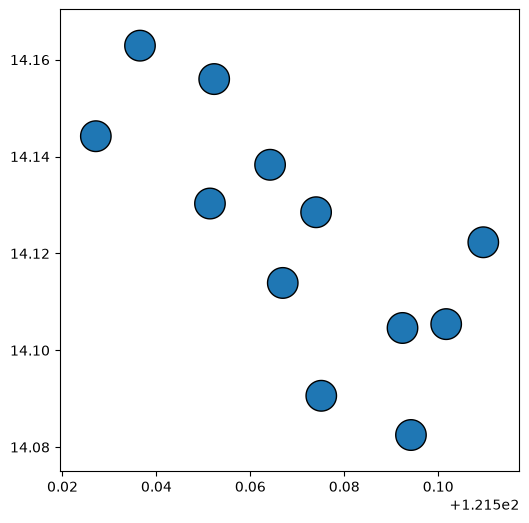

In [23]:
fig, ax = plt.subplots(figsize=(10,6))
gdf.plot(ax=ax, edgecolor="black")
plt.show()

## 1. Fix the zone_id column
Rename the zone_id column to match the zone_code column of other data frames

In [24]:
gdf = gdf.rename(columns={'zone_id': 'zone_code'})

## 2. Create a copy of household and risk_index data frames
Create a copy of household data frames with float data type for `households_with_access` and `total_households`

In [25]:
# shared column name
zone_code = 'zone_code'

# household column names
hh_total = 'total_households'
hh_access = 'households_with_access'

# risk index column names
r_score = 'risk_score'

# create a copy of household and risk_index data frame
hh_copy = household_df_clean[
    [zone_code, hh_total, hh_access]
].copy()

r_copy = risk_index_df_clean[
    [zone_code, r_score]
].copy()

hh_copy[[hh_total, hh_access]] = hh_copy[[hh_total, hh_access]].astype(float)

## 3. Create the demand data frame from requests

In [26]:
demand_sql = """
    SELECT
        CASE WHEN zone_code = 'A-03'
            THEN 'A03'
        ELSE zone_code
            END AS zone_code,
    COUNT(DISTINCT request_id) AS valid_requests
    FROM requests
    WHERE status IN ('verified', 'open')
    GROUP BY 1
    ORDER BY 1;
"""
with sqlite3.connect(SQL_FILENAME) as con:
    demand_df = pd.read_sql_query(demand_sql, con)

print(demand_df.to_string(index=False))

zone_code  valid_requests
      A01              23
      A02              29
      A03              36
      A04              14
      A05              17
      A06              32
      A07              35
      A08              28
      A09              40
      A10              11
      A11              32
      A12              25


## 4. Merge in the analysis dataframe

In [27]:
analysis = (gdf
    .merge(
        hh_copy,
        on=zone_code,
        how='left',
        validate='one_to_one'
    ).merge(
        r_copy,
        on=zone_code,
        how='left',
        validate='one_to_one'
    ).merge(
        demand_df,
        on=zone_code,
        how='left',
        validate='one_to_one'
    )
)
analysis.head(3)

,zone_code,zone_name,psgc_code,latitude,longitude,geometry_type,anchor_precision,geometry,total_households,households_with_access,risk_score,valid_requests
0,A01,Abang,0405623001,14.1303,121.5514,SIMULATED_350M_STUDY_CATCHMENT_NOT_OFFICIAL_BA...,approximate mapping reference point; not geode...,"POLYGON ((121.55464 14.13032, 121.55464 14.130...",850.0,520.0,40,23
1,A02,Aliliw,0405623002,14.1383,121.5642,SIMULATED_350M_STUDY_CATCHMENT_NOT_OFFICIAL_BA...,approximate mapping reference point; not geode...,"POLYGON ((121.56744 14.13832, 121.56744 14.138...",700.0,238.0,80,29
2,A03,Atulinao,0405623003,14.1223,121.6096,SIMULATED_350M_STUDY_CATCHMENT_NOT_OFFICIAL_BA...,approximate mapping reference point; not geode...,"POLYGON ((121.61284 14.12232, 121.61284 14.122...",500.0,228.0,66,36


## 5. Calculate service gap

In [28]:
analysis['valid_requests'] = analysis['valid_requests'].fillna(0).astype(int)

access_total_ratio = analysis[hh_access] / analysis[hh_total]
analysis['service_gap'] = 100 * (1 - access_total_ratio)

analysis[['service_gap', zone_code]]

,service_gap,zone_code
0,38.823529,A01
1,66.000000,A02
2,54.400000,A03
3,25.714286,A04
4,29.347826,A05
5,57.317073,A06
6,63.636364,A07
7,76.923077,A08
8,56.000000,A09
9,26.829268,A10


## 6. Ingtegrity Checks

In [29]:
assert (
    len(analysis) == 12
    and analysis[zone_code].is_unique
)

assert (
    analysis[
        [hh_access, hh_total, r_score]
    ].notna().all().all()
)

assert (analysis[hh_access] <= analysis[hh_total]).all()

assert analysis['service_gap'].between(0, 100).all()

print('Analysis Completed validation')

Analysis Completed validation


# Map Stuff

Facilities as points

In [30]:
fac_geometry = gpd.points_from_xy(
    facilities_df_clean['longitude'],
    facilities_df_clean['latitude']
)

fac_gdf = gpd.GeoDataFrame(
    facilities_df_clean,
    geometry=fac_geometry,
    crs=WGS84
).to_crs(METRIC_CRS)

Compute centroids

In [31]:
zones_m = analysis.to_crs(METRIC_CRS)
centroid = zones_m.geometry.centroid
centroid